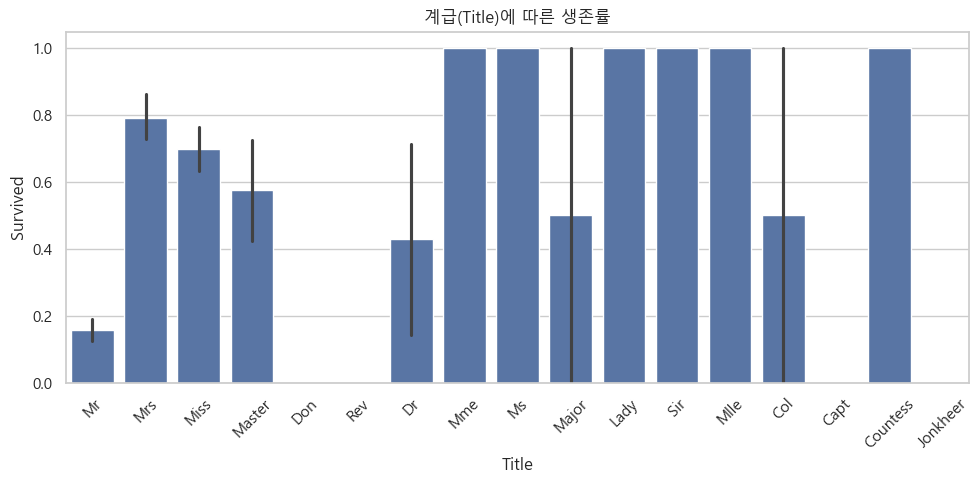

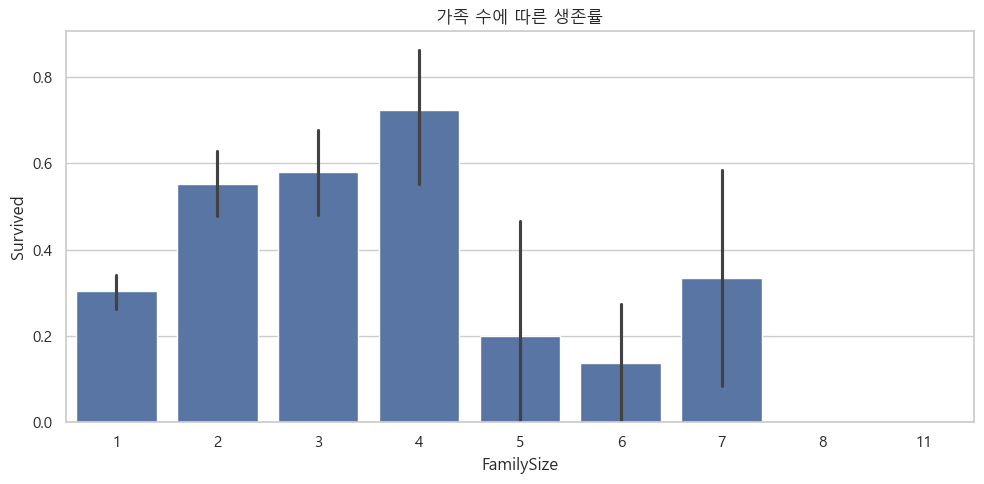

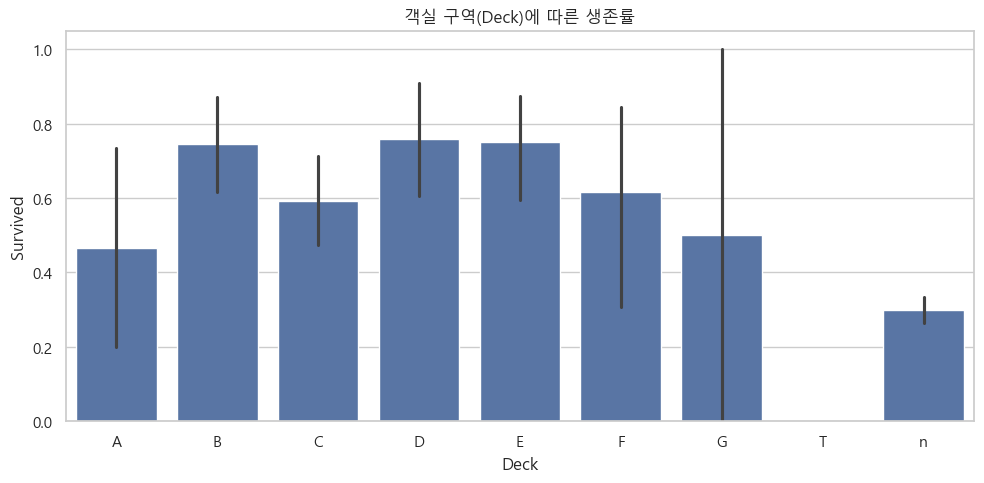

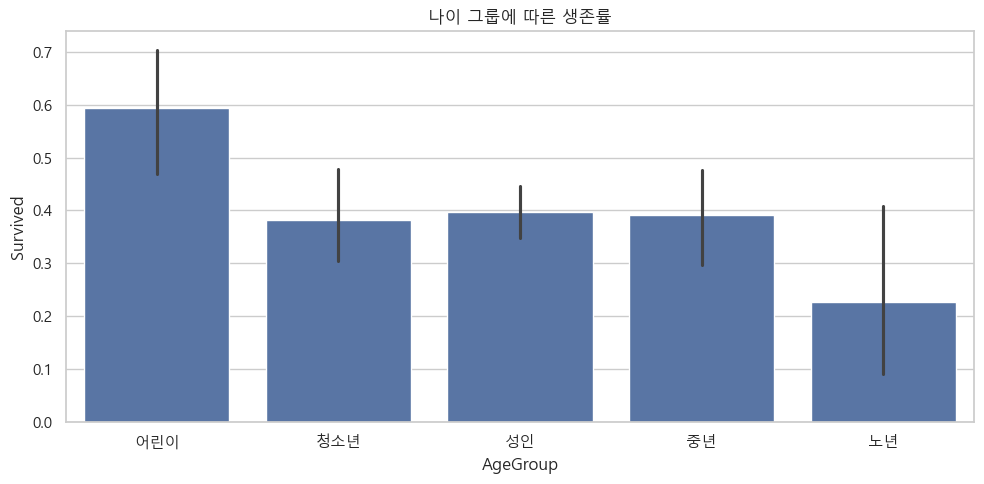

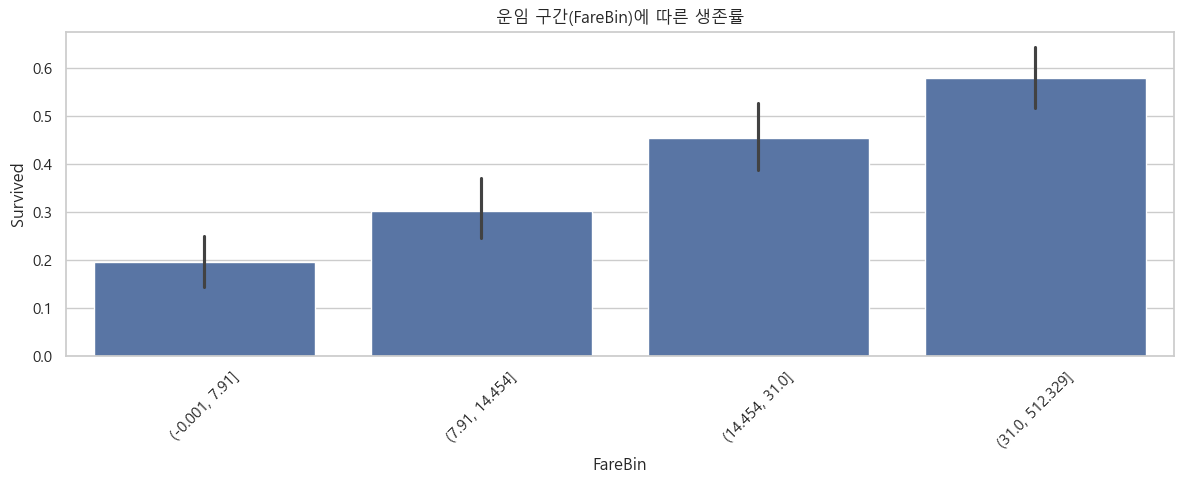

비극적 가족 생존 사례 (한 명만 생존한 가족들):
             FamilyID                                          Name  Survived
279          Abbott_3              Abbott, Mrs. Stanton (Rosa Hunt)         1
746          Abbott_3                   Abbott, Mr. Rossmore Edward         0
874         Abelson_2         Abelson, Mrs. Samuel (Hannah Wizosky)         1
308         Abelson_2                           Abelson, Mr. Samuel         0
855             Aks_2                    Aks, Mrs. Sam (Leah Rosen)         1
..                ...                                           ...       ...
830         Yasbeck_2       Yasbeck, Mrs. Antoni (Selini Alexander)         1
620         Yasbeck_2                           Yasbeck, Mr. Antoni         0
325           Young_1                      Young, Miss. Marie Grice         1
559  de Messemaeker_2  de Messemaeker, Mrs. Guillaume Joseph (Emma)         1
286       de Mulder_1                       de Mulder, Mr. Theodore         1

[285 rows x 3 columns]


In [25]:
# 타이타닉 생존자 데이터 EDA 

# 분석 목표: 타이타닉 탑승자 중 누가 살아남았는가?

# 데이터를 통해 생존에 영향을 준 요소를 파악하는 탐색적 분석을 수행했고
# 추가로, 이름의 계급, 가족 구성, 객실 위치, 요금 분포 등 특이 분석을 포함
# 마지막으로 연인/가족 단위로 비극적 생존 시나리오 분석을 포함시켰습니다.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.font_manager as fm
import matplotlib as mpl

# 한글 폰트 설정
font_path = 'C:/Windows/Fonts/malgun.ttf'
font_name = fm.FontProperties(fname=font_path).get_name()
mpl.rcParams['font.family'] = font_name
mpl.rcParams['axes.unicode_minus'] = False

# 데이터 불러오기
train = pd.read_csv("train.csv")

# 1. 이름 속 계급 (Title) 추출 및 분석
train['Title'] = train['Name'].str.extract(' ([A-Za-z]+)\\.', expand=False)
plt.figure(figsize=(10, 5))
sns.barplot(x='Title', y='Survived', data=train, estimator=lambda x: sum(x) / len(x))
plt.title('계급(Title)에 따른 생존률')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2. 가족 수 기반 분석 (FamilySize)
train['FamilySize'] = train['SibSp'] + train['Parch'] + 1
plt.figure(figsize=(10, 5))
sns.barplot(x='FamilySize', y='Survived', data=train)
plt.title('가족 수에 따른 생존률')
plt.tight_layout()
plt.show()

# 3. Cabin → 객실 위치 (Deck) 분석
train['Deck'] = train['Cabin'].astype(str).str[0]

# 알파벳 순서로 직접 정렬 정의
deck_order = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'T', 'n']

plt.figure(figsize=(10, 5))
sns.barplot(x='Deck', y='Survived', data=train, order=deck_order)
plt.title('객실 구역(Deck)에 따른 생존률')
plt.tight_layout()
plt.show()


# 4. 운임 요금 구간 분석 (FareBin)
train['FareBin'] = pd.qcut(train['Fare'], 4)
plt.figure(figsize=(12, 5))
sns.barplot(x='FareBin', y='Survived', data=train)
plt.title('운임 구간(FareBin)에 따른 생존률')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 5. 연인/가족 단위 비극적 생존 시나리오 분석
# 성, 가족 수, 성을 기반으로 가족 ID 생성
train['Surname'] = train['Name'].apply(lambda x: x.split(',')[0])
train['FamilyID'] = train['Surname'] + '_' + train['FamilySize'].astype(str)

# 가족별 생존자 수 계산
family_survival = train.groupby('FamilyID')['Survived'].sum()
family_size = train.groupby('FamilyID')['Survived'].count()

# 단 1명만 생존한 가족만 추출 (비극적 구조 상황)
sad_families = family_survival[family_survival == 1]
sad_family_ids = sad_families.index.tolist()
tragic_cases = train[train['FamilyID'].isin(sad_family_ids)]

# 결과 확인
print("비극적 가족 생존 사례 (한 명만 생존한 가족들):")
print(tragic_cases[['FamilyID', 'Name', 'Survived']].sort_values(by='FamilyID'))
